In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sys
sys.path.append('../')
from src.ConstitutiveModel import DebyeModel
from src.PlaneWave import PlaneWave
from src.LayeredColumn import LayeredColumn
from src.ConstitutiveModel import MixingModel

%reload_ext autoreload
%autoreload 2

# Layered model

In [2]:
# add LayeredColumn
# define constitutive models
omega_run  = 2 * np.pi * np.logspace(6, 9, 1000)  # frequency range from 1 Mhz to 1 GHz
omega_plot = 2 * np.pi * np.array([1e6, 1e7, 1e8, 1e9]) # for plotting
f      = omega_run / (2 * np.pi)
f_plot = omega_plot / (2 * np.pi)

# ------------- clean ice ---------------
ice_eps_infty = 3.15
ice_eps_s = 75
ice_delta_eps = ice_eps_s - ice_eps_infty
ice_sigma_s = 1e-9
ice_fr = 5e3 
ice_omega_r = 2 * np.pi * ice_fr
ice_tau = 1 / ice_omega_r

clean_ice_model = DebyeModel(
    eps_infty=ice_eps_infty,
    delta_eps=ice_delta_eps,
    sigma_s=ice_sigma_s,
    tau_0=ice_tau)
clean_ice_fn = lambda omega: clean_ice_model.debye(omega)[0]

# ------------- debris ladden ice ---------------
# These are sensitivity-test values, not a calibrated rock model.
rock_eps_infty = 6.0
rock_eps_s = 10.0
rock_fr = 1e6       # relaxation frequency [Hz]
rock_sigma = 1e-5  # DC conductivity [S/m]
rock_tau = 1 / (2 * np.pi * rock_fr)

rock_model = DebyeModel(
    eps_infty=rock_eps_infty,
    delta_eps=rock_eps_s - rock_eps_infty,
    sigma_s=rock_sigma,
    tau_0=rock_tau,
)

rock_fn = lambda omega: rock_model.debye(omega)[0]

# mixture model
mixing_model = MixingModel(
    inclusion_model=rock_fn,
    host_model=clean_ice_fn,
    fraction=0.05,  # rock volume fraction
)

# --------------- bedrock ---------------
# this re-uses rock_fn
bedrock_fn = rock_fn

H = 2e3 # ice thickness
h = 100 # dirty ice thickness
sigma = 1e-4 # ice static conductivity

clean_ice = PlaneWave(
    H = H, 
    s = 0,
    sigma = sigma, 
    model = clean_ice_fn
)
dirty_ice = PlaneWave(
    H = h,
    s = clean_ice.b,
    sigma=0.0,  
    model=mixing_model.maxwell_garnett,
)
bed = PlaneWave(
    H = H,
    s = dirty_ice.b,
    sigma = sigma,
    model = bedrock_fn
)
waves = [clean_ice, dirty_ice, bed]
layered_column = LayeredColumn(waves)
layered_column.show_geometry()
layered_column.show_permittivity(omega_plot)

Surface: 0, Base: 4100.0 m below surface
Layer 1: s = 0, b = 2000.0
Layer 2: s = 2000.0, b = 2100.0
Layer 3: s = 2100.0, b = 4100.0


IndexError: invalid index to scalar variable.

Reference round-trip delay: 1.205 µs


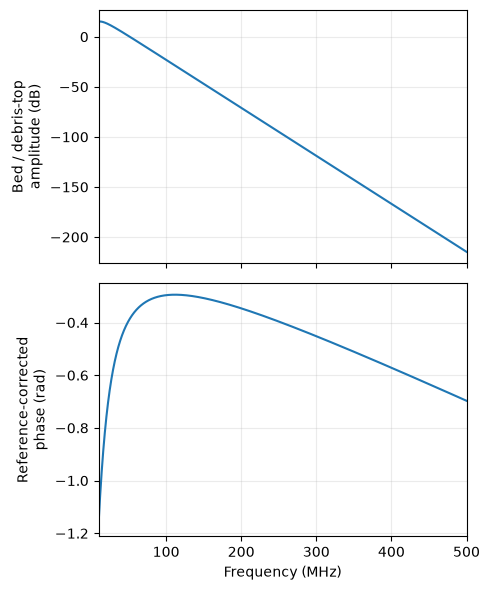

In [3]:
f_mhz = np.linspace(10.0, 500.0, 20_001)
omega = 2.0 * np.pi * f_mhz * 1e6

spec = layered_column.spectral_ratio(omega, n_ref=1.8059)
print(f"Reference round-trip delay: {spec['tau_ref_s'] * 1e6:.3f} µs")

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(5, 6))

ax[0].plot(f_mhz, spec["amplitude_db"])
ax[0].set_ylabel("Bed / debris-top\namplitude (dB)")

ax[1].plot(f_mhz, spec["phase_corrected_rad"])
ax[1].set_ylabel("Reference-corrected\nphase (rad)")
ax[1].set_xlabel("Frequency (MHz)")
ax[1].set_xlim(10, 500)

for a in ax:
    a.grid(alpha=0.25)

fig.tight_layout()
plt.savefig("../fig/spectral_ratio.png")
plt.show()


# Adding thermal influence

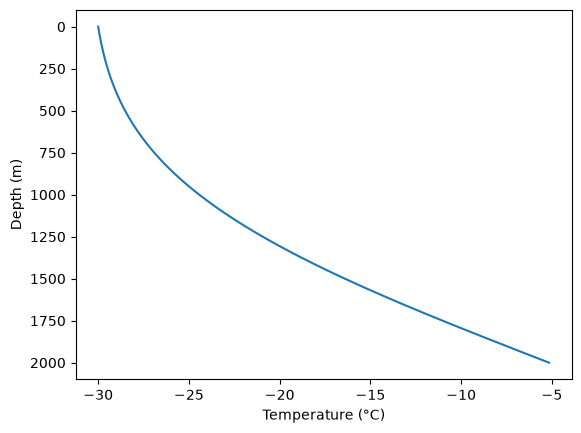

In [4]:
from src.Thermal import robin_temperature


z = np.linspace(0, 2000, 501)
T = robin_temperature(
    z, H=2000, T_surface=-30.0,
    accumulation_m_per_yr=0.10, q_b=0.050,
)

plt.plot(T, z)
plt.gca().invert_yaxis()
plt.xlabel("Temperature (°C)")
plt.ylabel("Depth (m)")
plt.show()

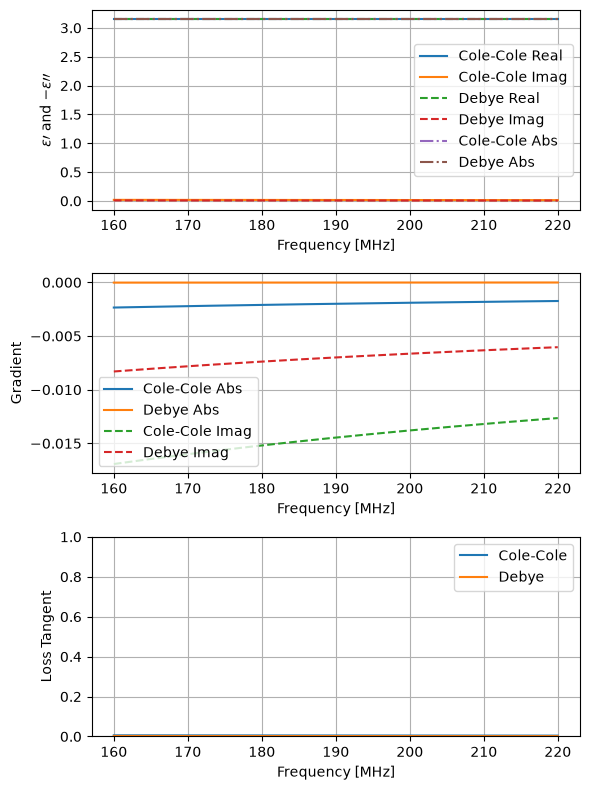

In [20]:
# Cole Cole model
from src.ConstitutiveModel import ColeColeModel, DebyeModel

T = 273

# parameters are from Dawson et al 2026/2027 Fig.7
eps_s_1 = 75
eps_s_2 = 100
f1 = 5000
f2 = 500
alpha1 = 0.05
alpha2 = 0.1

delta_eps = [eps_s_1 - clean_ice_model.eps_infty, 
             eps_s_2 - clean_ice_model.eps_infty]

tau_0_1 = 1 / (2 * np.pi * f1)
tau_0_2 = 1 / (2 * np.pi * f2)

cc = ColeColeModel(
    eps_infty=clean_ice_model.eps_infty,
    delta_eps=delta_eps,
    sigma_s=1e-9,
    alpha=[alpha1, alpha2],
    T=T
)

debye = DebyeModel(
    eps_infty=clean_ice_model.eps_infty,
    delta_eps=delta_eps,
    sigma_s=1e-9,
    T=T
)

# omega = np.logspace(7, 8, 100) 
f = np.linspace(160e6, 220e6, 1000)
omega = f * 2 * np.pi
eps_cc     = cc.cole_cole(omega)
eps_debye  = debye.debye(omega)
loss_cc    = cc.loss_tangent(omega) 
loss_debye = debye.loss_tangent(omega) 

plt.figure(figsize=(6, 8))
plt.subplot(3,1,1)
# plt.semilogx(omega, eps_cc.real)
# plt.semilogx(omega, -eps_cc.imag)
# plt.semilogx(omega, eps_debye.real,'--')
# plt.semilogx(omega, -eps_debye.imag, '--')
# plt.semilogx(omega, np.abs(eps_cc), '-.')
# plt.semilogx(omega, np.abs(eps_debye), '-.')
plt.plot(f/1e6, eps_cc.real)
plt.plot(f/1e6, -eps_cc.imag)
plt.plot(f/1e6, eps_debye.real,'--')
plt.plot(f/1e6, -eps_debye.imag, '--')
plt.plot(f/1e6, np.abs(eps_cc), '-.')
plt.plot(f/1e6, np.abs(eps_debye), '-.')
plt.xlabel('Frequency [MHz]')
plt.ylabel(f'$\epsilon\prime$ and $-\epsilon\prime\prime$')
plt.legend(['Cole-Cole Real', 'Cole-Cole Imag', 'Debye Real', 'Debye Imag', 'Cole-Cole Abs', 'Debye Abs'])
plt.grid(True)

# find the gradient of the absolute permittivity and imaginary part
grad_abs_cc = np.gradient(np.abs(eps_cc), np.log(omega))
grad_abs_debye = np.gradient(np.abs(eps_debye), np.log(omega))
grad_imag_cc = np.gradient(-eps_cc.imag, np.log(omega))
grad_imag_debye = np.gradient(-eps_debye.imag, np.log(omega))
plt.subplot(3,1,2)
# plt.semilogx(omega, grad_abs_cc)
# plt.semilogx(omega, grad_abs_debye)
# plt.semilogx(omega, grad_imag_cc ,'--')
# plt.semilogx(omega, grad_imag_debye, '--')
plt.plot(f/1e6, grad_abs_cc)
plt.plot(f/1e6, grad_abs_debye)
plt.plot(f/1e6, grad_imag_cc ,'--')
plt.plot(f/1e6, grad_imag_debye, '--')
plt.xlabel('Frequency [MHz]')
plt.ylabel('Gradient')
plt.legend(['Cole-Cole Abs', 'Debye Abs', 'Cole-Cole Imag', 'Debye Imag'])
plt.grid(True)

plt.subplot(3,1,3)
# plt.semilogx(omega, loss_cc)
# plt.semilogx(omega, loss_debye)
plt.plot(f/1e6, loss_cc)
plt.plot(f/1e6, loss_debye)
plt.xlabel('Frequency [MHz]')
plt.ylabel('Loss Tangent')
plt.ylim([0, 1])
plt.legend(['Cole-Cole', 'Debye'])
plt.tight_layout()
plt.savefig("../fig/colecole-debye-HiCAR.png",dpi=300)
plt.grid(True)

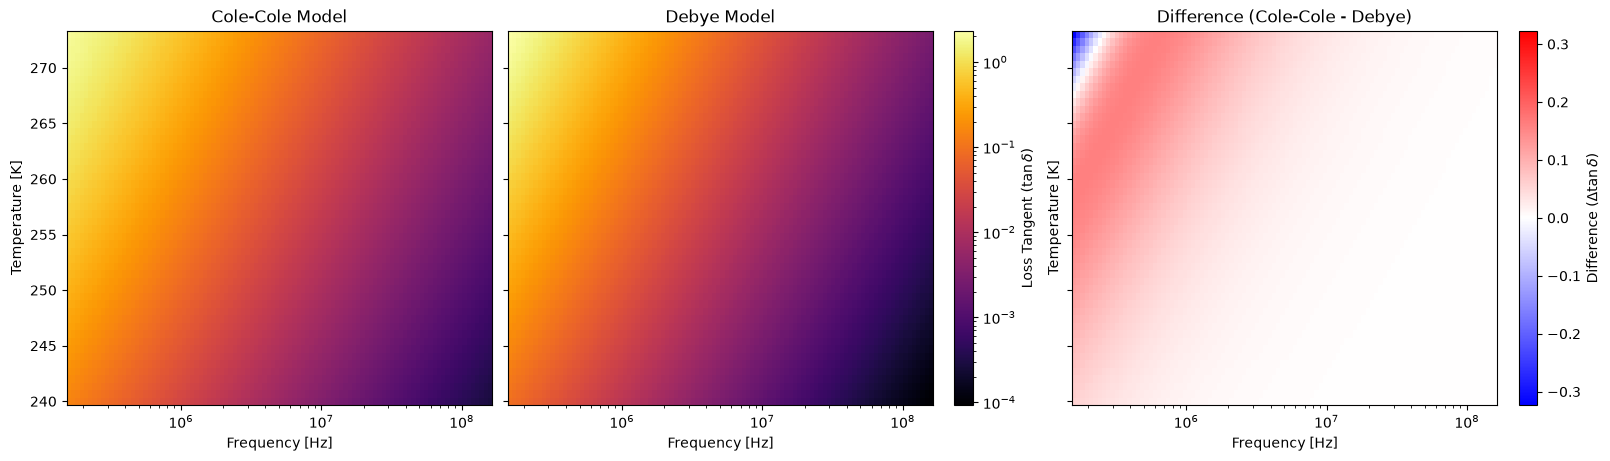

In [21]:
from matplotlib.colors import LogNorm
omega = np.logspace(6, 9, 100)       # [rad/s]
temps = np.linspace(240, 273, 50)    # [K]
linear_f = omega / (2 * np.pi)

# Model parameters (from Dawson et al., Fig. 7)
eps_s_1, eps_s_2 = 75, 100
alpha1, alpha2 = 0.05, 0.1
delta_eps = [
    eps_s_1 - clean_ice_model.eps_infty,
    eps_s_2 - clean_ice_model.eps_infty,
]

# Preallocate loss tangent arrays: shape (len(temps), len(omega))
loss_cc_map = np.zeros((len(temps), len(omega)))
loss_debye_map = np.zeros((len(temps), len(omega)))

for i, T in enumerate(temps):
    cc = ColeColeModel(
        eps_infty=clean_ice_model.eps_infty,
        delta_eps=delta_eps,
        sigma_s=1e-9,
        alpha=[alpha1, alpha2],
        T=T,
    )
    debye = DebyeModel(
        eps_infty=clean_ice_model.eps_infty,
        delta_eps=delta_eps,
        sigma_s=1e-9,
        T=T,
    )
    loss_cc_map[i, :] = cc.loss_tangent(omega)
    loss_debye_map[i, :] = debye.loss_tangent(omega)

# Shared color scale limits (clipping tiny values for LogNorm)
vmin = max(1e-5, min(loss_cc_map.min(), loss_debye_map.min()))
vmax = max(loss_cc_map.max(), loss_debye_map.max())
norm = LogNorm(vmin=vmin, vmax=vmax)

# Plot side-by-side heatmaps
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, constrained_layout=True)

pcm1 = axes[0].pcolormesh(linear_f, temps, loss_cc_map, norm=norm, shading="auto", cmap="inferno")
axes[0].set_xscale("log")
axes[0].set_title("Cole-Cole Model")
axes[0].set_xlabel("Frequency [Hz]")
axes[0].set_ylabel("Temperature [K]")

pcm2 = axes[1].pcolormesh(linear_f, temps, loss_debye_map, norm=norm, shading="auto", cmap="inferno")
axes[1].set_xscale("log")
axes[1].set_title("Debye Model")
axes[1].set_xlabel("Frequency [Hz]")

diff_map = loss_cc_map - loss_debye_map
pcm3 = axes[2].pcolormesh(linear_f, temps, diff_map, shading="auto", cmap="bwr", vmin=-np.max(np.abs(diff_map)), vmax=np.max(np.abs(diff_map)))
axes[2].set_xscale("log")
axes[2].set_title("Difference (Cole-Cole - Debye)")
axes[2].set_xlabel("Frequency [Hz]")
axes[2].set_ylabel("Temperature [K]")

cbar = fig.colorbar(pcm2, ax=axes[1], label=r"Loss Tangent ($\tan\delta$)")
cbar3 = fig.colorbar(pcm3, ax=axes[2], label=r"Difference ($\Delta\tan\delta$)")
plt.show()


# Power spectrum and phase curvature analysis with dispersive materials

Surface: 0.0, Base: 4101.0 m below surface
Surface: 0.0, Base: 4101.0 m below surface


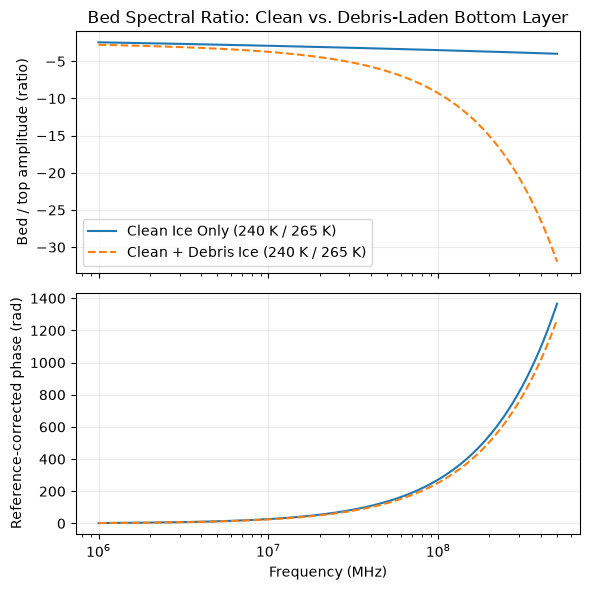

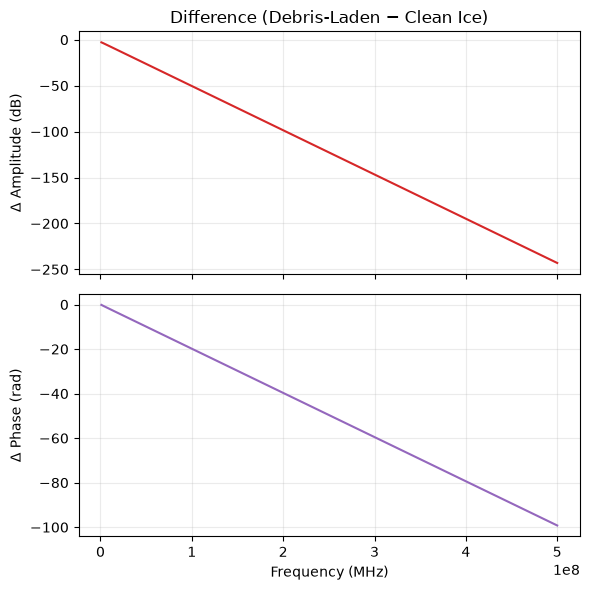

In [45]:

# --- 1. Shared Parameters ---
# T_top = 240.0  # [K] colder top layer
# T_bot = 265.0  # [K] warmer bottom layer
T_top = 240
T_bot = T_top # homogenous temperature experiment

H_air = 1.0
H = 2e3        # [m] top layer thickness
h = 100.0      # [m] bottom layer thickness
# sigma = 1e-5   # [S/m] static conductivity for PlaneWave

# Cole-Cole ice parameters (from Dawson et al., Fig. 7)
ice_eps_infty = 3.15
ice_delta_eps = [75.0 - ice_eps_infty, 100.0 - ice_eps_infty]
ice_alpha = [0.05, 0.1]
ice_sigma_s = 1e-9
sigma = ice_sigma_s

# --- 2. Temperature-Dependent Clean Ice Models (Cole-Cole) ---
cc_ice_top = ColeColeModel(
    eps_infty=ice_eps_infty,
    delta_eps=ice_delta_eps,
    sigma_s=ice_sigma_s,
    alpha=ice_alpha,
    T=T_top,
)

cc_ice_bot = ColeColeModel(
    eps_infty=ice_eps_infty,
    delta_eps=ice_delta_eps,
    sigma_s=ice_sigma_s,
    alpha=ice_alpha,
    T=T_bot,
)

# --- 3. Rock & Debris-Laden Ice Models ---
rock_eps_infty = 6.0
rock_eps_s = 10.0
rock_fr = 1e6
rock_sigma = 1e-5
rock_tau = 1.0 / (2.0 * np.pi * rock_fr)

rock_model = DebyeModel(
    eps_infty=rock_eps_infty,
    delta_eps=rock_eps_s - rock_eps_infty,
    sigma_s=rock_sigma,
    tau_0=rock_tau,
)
rock_fn = lambda omega: rock_model.debye(omega)[0]
bedrock_fn = rock_fn

# Debris-laden bottom layer uses warmer ice (T_bot) as the host
mixing_model = MixingModel(
    inclusion_model=rock_fn,
    host_model=cc_ice_bot.cole_cole,
    fraction=0.05,
)

# --- 4. Build Both Layered Columns ---
# Scenario 1: Clean ice (top, 240 K) + Clean ice (bottom, 265 K)
col_clean = LayeredColumn([
    PlaneWave(H=H_air, s=0.0, sigma=0.0, model=lambda w: np.ones_like(w, dtype=complex)), # air
    PlaneWave(H=H, s=H_air, sigma=sigma, model=cc_ice_top.cole_cole),
    PlaneWave(H=h, s=H_air + H, sigma=sigma, model=cc_ice_bot.cole_cole),
    PlaneWave(H=H, s=H_air + H + h, sigma=sigma, model=bedrock_fn),
])

# Scenario 2: Clean ice (top, 240 K) + Debris-laden ice (bottom, 265 K)
col_debris = LayeredColumn([
    PlaneWave(H=H_air, s=0.0, sigma=0.0, model=lambda w: np.ones_like(w, dtype=complex)), # air
    PlaneWave(H=H, s=H_air, sigma=sigma, model=cc_ice_top.cole_cole),
    PlaneWave(H=h, s=H_air + H, sigma=rock_sigma, model=mixing_model.maxwell_garnett),
    PlaneWave(H=H, s=H_air + H + h, sigma=sigma, model=bedrock_fn),
])

# --- 5. Compute Spectral Ratios ---
f_mhz = np.linspace(1e6, 5e8, 20_001)
omega = 2.0 * np.pi * f_mhz

spec_clean = col_clean.spectral_ratio(omega, deep=2, n_ref=1.8059)
spec_debris = col_debris.spectral_ratio(omega, deep=2, n_ref=1.8059)

# --- 6. Plot 1: Comparison of Both Scenarios ---
fig1, ax1 = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

ax1[0].semilogx(f_mhz, np.log(np.abs(spec_clean["ratio"])), label="Clean Ice Only (240 K / 265 K)")
ax1[0].semilogx(f_mhz, np.log(np.abs(spec_debris["ratio"])), "--", label="Clean + Debris Ice (240 K / 265 K)")
ax1[0].set_ylabel("Bed / top amplitude (ratio)")
ax1[0].set_title("Bed Spectral Ratio: Clean vs. Debris-Laden Bottom Layer")
ax1[0].legend()

ax1[1].semilogx(f_mhz, spec_clean["phase_corrected_rad"], label="Clean Ice Only")
ax1[1].semilogx(f_mhz, spec_debris["phase_corrected_rad"], "--", label="Clean + Debris Ice")
ax1[1].set_ylabel("Reference-corrected phase (rad)")
ax1[1].set_xlabel("Frequency (MHz)")

for a in ax1:
    a.grid(alpha=0.25)

fig1.tight_layout()
plt.savefig("../fig/spectral_ratio_comparison.png")
plt.show()

# --- 7. Plot 2: Difference (Debris-Laden minus Clean Ice) ---
diff_amp_db = spec_debris["amplitude_db"] - spec_clean["amplitude_db"]
diff_phase_rad = spec_debris["phase_corrected_rad"] - spec_clean["phase_corrected_rad"]

fig2, ax2 = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

ax2[0].plot(f_mhz, diff_amp_db, color="tab:red")
ax2[0].set_ylabel(r"$\Delta$ Amplitude (dB)")
ax2[0].set_title("Difference (Debris-Laden − Clean Ice)")

ax2[1].plot(f_mhz, diff_phase_rad, color="tab:purple")
ax2[1].set_ylabel(r"$\Delta$ Phase (rad)")
ax2[1].set_xlabel("Frequency (MHz)")

for a in ax2:
    a.grid(alpha=0.25)

fig2.tight_layout()
plt.savefig("../fig/spectral_ratio_difference.png")
plt.show()


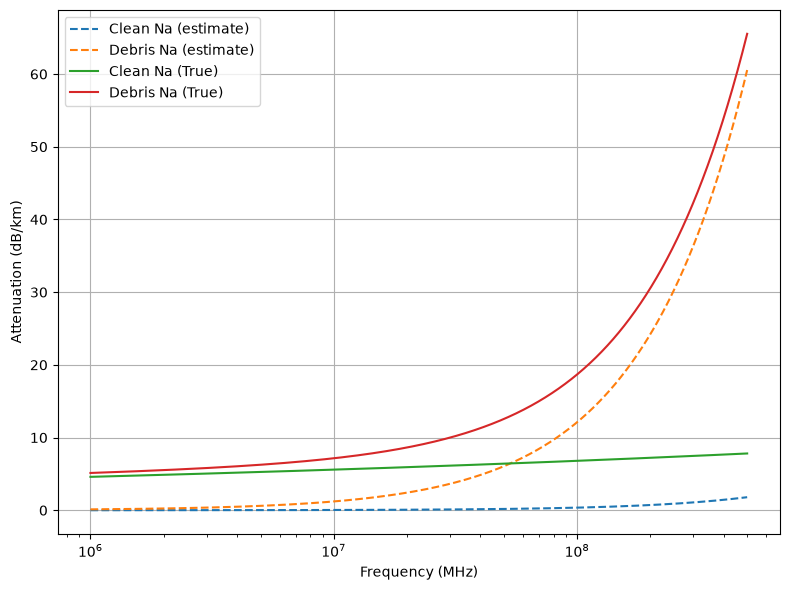

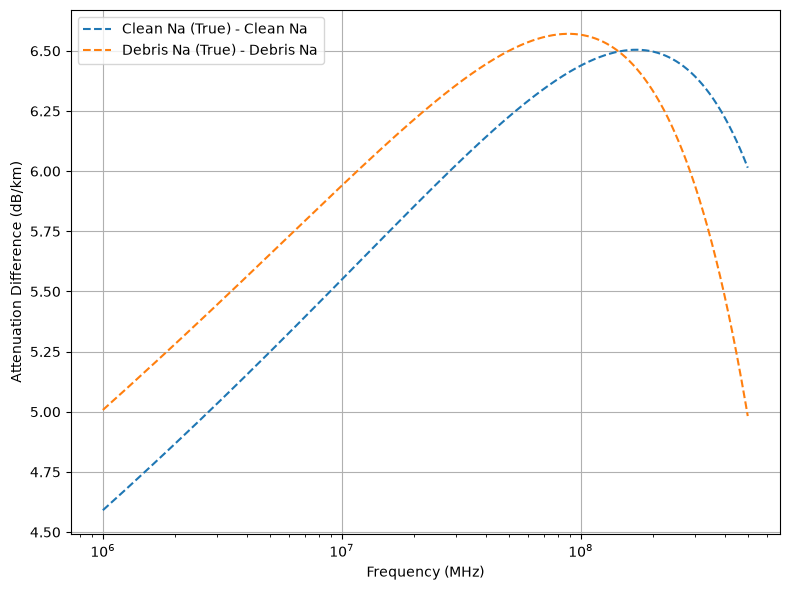

In [46]:
from src.SpectralRatioApprox import SpectralRatioApprox
# compute the inverted attenuation rate from spectral ratio
v_ice = 3e8 / np.sqrt(ice_eps_infty)
tt = (col_clean.base - col_clean.surface) / v_ice
twtt = tt

# estimated attenuation rate from spectral ratio
sra = SpectralRatioApprox(omega, tt)
clean_Na, clean_Na_low_loss = sra.attenuation_rate(spec_clean["ratio"])
debris_Na, debris_Na_low_loss = sra.attenuation_rate(spec_debris["ratio"]) 

# true attenuation rate for clean and debris ice from the layered column
clean_atten_rate_true = col_clean.attenuation_rate(omega)
debris_atten_rate_true = col_debris.attenuation_rate(omega)

plt.figure(figsize=(8, 6))
plt.semilogx(f_mhz, clean_Na, "--")
plt.semilogx(f_mhz, debris_Na, "--")
plt.semilogx(f_mhz, clean_atten_rate_true)
plt.semilogx(f_mhz, debris_atten_rate_true)
plt.xlabel("Frequency (MHz)")
plt.ylabel("Attenuation (dB/km)")
plt.legend(["Clean Na (estimate)", "Debris Na (estimate)", "Clean Na (True)", "Debris Na (True)"])
plt.tight_layout()
plt.grid(True)
plt.savefig("../fig/attenuation_comparison.png")

plt.figure(figsize=(8, 6))
# plot the difference between 
plt.semilogx(f_mhz, clean_atten_rate_true - clean_Na, "--")
plt.semilogx(f_mhz, debris_atten_rate_true - debris_Na, "--")
plt.legend(["Clean Na (True) - Clean Na", "Debris Na (True) - Debris Na"])
plt.xlabel("Frequency (MHz)")
plt.ylabel("Attenuation Difference (dB/km)")
plt.tight_layout()
plt.grid(True)


# bias of spectral ratio

In [47]:
def alpha_bias(omega, depsppdw, sigma_s, eps_infty = 3.15):
    """
    Bias in the spectral ratio estimate 
    """
    c = 3e8
    eps_0 = 8.854e-12

    prefactor = 1 / (2 * c * eps_0 * np.sqrt(eps_infty))
    return prefactor * (omega**2 * depsppdw * eps_0 - sigma_s)

depsdw = cc_ice_bot.grad_imag(omega)
sigma_s_vec = ice_sigma_s * np.ones_like(omega)
alpha_biases = [alpha_bias(omega_i, grad_i, sigma_s_i) for omega_i, grad_i, sigma_s_i in zip(omega, depsdw, sigma_s_vec)]
Na_biases = np.array(alpha_biases) * (-8686) # dB/km

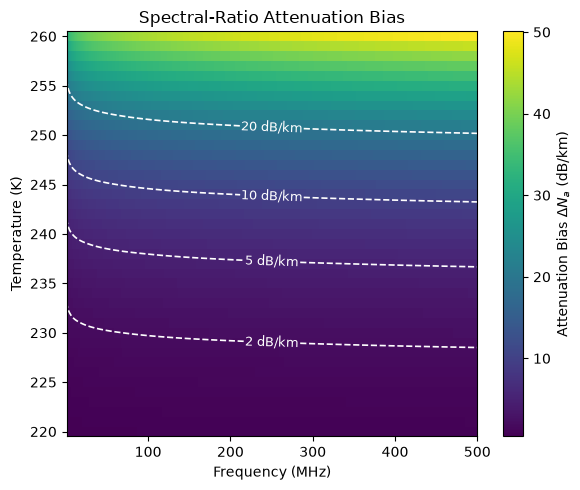

In [60]:
T_vals = np.linspace(220, 260, 41)  # 1 K steps
Na_bias_grid = np.zeros((len(T_vals), len(omega)))

sigma_s_vec = ice_sigma_s * np.ones_like(omega)

# 2. Run parametric sweep
for i, T_val in enumerate(T_vals):
    cc_model = ColeColeModel(
        eps_infty=ice_eps_infty,
        delta_eps=ice_delta_eps,
        sigma_s=ice_sigma_s,
        alpha=ice_alpha,
        T=float(T_val),
    )
    depsppdw = cc_model.grad_imag(omega)

    biases = [
        alpha_bias(w, g, s, eps_infty=ice_eps_infty)
        for w, g, s in zip(omega, depsppdw, sigma_s_vec)
    ]
    Na_bias_grid[i, :] = np.array(biases) * (-8686)  # Convert Np/m to dB/km

# 3. Plot heatmap
fig, ax = plt.subplots(figsize=(6, 5))

# Convert f_mhz to MHz if it's currently in Hz (e.g., 1e6 to 5e8)
f_plot = f_mhz / 1e6 if np.max(f_mhz) > 1e4 else f_mhz

pcm = ax.pcolormesh(
    f_plot,
    T_vals,
    Na_bias_grid,
    shading="auto",
    cmap="viridis",
)

# Add contour lines at 2, 5, 10, 20 dB/km
levels = [2, 5, 10, 20]
cs = ax.contour(
    f_plot,
    T_vals,
    Na_bias_grid,
    levels=levels,
    colors="white",
    linewidths=1.2,
    linestyles="--",
)

# Place each label at the midpoint of its longest contour segment
manual_locs = []
for segs in cs.allsegs:
    if segs:
        longest_seg = max(segs, key=len)
        mid_idx = len(longest_seg) // 2
        manual_locs.append(tuple(longest_seg[mid_idx]))

ax.clabel(cs, inline=True, fontsize=9, fmt="%g dB/km", manual=manual_locs)

cbar = fig.colorbar(pcm, ax=ax, label=r"Attenuation Bias $\Delta N_a$ (dB/km)")
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Temperature (K)")
ax.set_title("Spectral-Ratio Attenuation Bias")

plt.tight_layout()
plt.savefig("../fig/attenuation_bias_heatmap.png")
plt.show()
